Mounted at /content/drive
✅ Securely loaded 112163 cumulative traces for validation lookup!


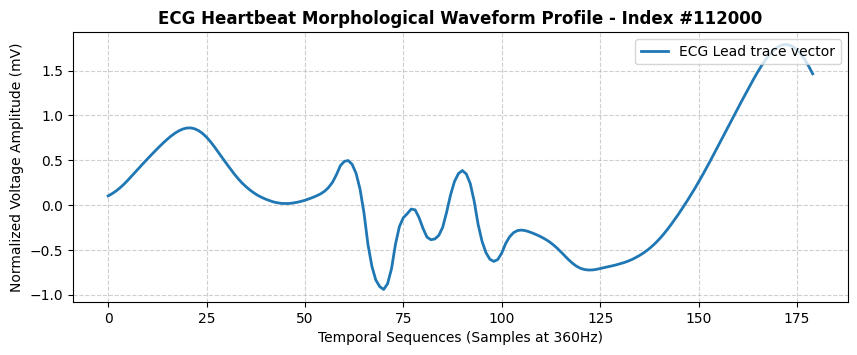


                     QUANTUM REAL-TIME DIAGNOSTIC MONITOR                     
 🔹 Selected Evaluation Row Index : #112000
 🔹 Signal Trace Registry Origin  : Local Hospital Clinical Registry
 🔹 ACTUAL Clinical Ground Truth  : PVC
 🔹 QNN PREDICTED Condition Class : PVC
 🔹 Prediction Verification Status: ✅ MATCH SUCCESS
 🔹 Quantum Circuit Certainty     : 84.31%
 🔹 Automated Evaluated Status    : HIGH RISK
-------------------------------------------------------------------------------------
 Patient-Friendly Diagnostic Guidance Advisory Details:
 "Ventricular Premature Beat (Early ventricular ectopic firing sequence captured). Lower chambers generated an independent pulse boundary. Monitor closely if recurring frequently."



In [ ]:
# ==============================================================================
# HOSPITAL SANDBOX RUN: REAL-TIME QUANTUM RISK ASSESSMENT TERMINAL
# ==============================================================================

# 1. Mount Google Drive First
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 2. Install Required Quantum Framework Dependencies
!pip install pennylane --quiet

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pennylane as qml

# ==============================================================================
# STEP 3: ESTABLISH SANDBOX VERIFIED DIRECTORY PATHS
# ==============================================================================
SANDBOX_DIR = "/content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun"
DATASETS_DIR = os.path.join(SANDBOX_DIR, "datasets")
MODELS_DIR = os.path.join(SANDBOX_DIR, "models")

# Define clinical class maps and matching patient-friendly advisory scripts
class_names = ["Normal", "LBBB", "RBBB", "APB", "PVC"]

clinical_guidance = {
    "Normal": "Normal sinus behavior detected. Clear conduction pathways across chambers. Continue routine observation metrics.",
    "LBBB": "Left Bundle Branch Block pattern recorded. Conduction delayed along the left ventricle walls. Clinical evaluation recommended to check underlying structural conditions.",
    "RBBB": "Right Bundle Branch Block signature detected. Electrical signals delayed traveling to the right ventricle chamber. Often benign, but routine ECG monitoring advised.",
    "APB": "Atrial Premature Beat (Early atrial firing contraction observed). The upper chambers contracted ahead of sequence. Avoid high-caffeine stimulants and track pattern recurrence.",
    "PVC": "Ventricular Premature Beat (Early ventricular ectopic firing sequence captured). Lower chambers generated an independent pulse boundary. Monitor closely if recurring frequently."
}

# ==============================================================================
# STEP 4: RECONSTRUCT MODEL ARCHITECTURES (1D-CNN + QUANTUM ANSATZ)
# ==============================================================================
class ECG1DCNNFeatureExtractor(nn.Module):
    def __init__(self, input_length=180, feature_dim=16):
        super(ECG1DCNNFeatureExtractor, self).__init__()
        self.conv_block = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Flatten()
        )
        self.fc_out = nn.Linear(32 * 45, feature_dim)
        self.classifier = nn.Linear(feature_dim, 5)

    def forward(self, x):
        features = self.conv_block(x)
        features = self.fc_out(features)
        logits = self.classifier(features)
        return features, logits

num_qubits = 4
num_layers = 2
dev = qml.device("default.qubit", wires=num_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(num_qubits), rotation='X')
    for l in range(num_layers):
        for i in range(num_qubits):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        for i in range(num_qubits - 1):
            qml.CNOT(wires=[i, i + 1])
        if num_qubits > 2:
            qml.CNOT(wires=[num_qubits - 1, 0])
    return [qml.expval(qml.PauliZ(i)) for i in range(num_qubits)]

class HybridQNNClassifier(nn.Module):
    def __init__(self):
        super(HybridQNNClassifier, self).__init__()
        self.pre_quantum_dense = nn.Linear(16, num_qubits)
        weight_shapes = {"weights": (num_layers, num_qubits, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_quantum_dense = nn.Linear(num_qubits, 5)

    def forward(self, x):
        x = torch.tanh(self.pre_quantum_dense(x))
        x = self.quantum_layer(x)
        logits = self.post_quantum_dense(x)
        return logits

# Initialize processing devices
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reconstruct and load weights for the 1D-CNN Feature Extractor
cnn_model = ECG1DCNNFeatureExtractor(input_length=180, feature_dim=16).to(device)
cnn_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "best_model.pt"), map_location=device))
cnn_model.eval()

# Reconstruct and load weights for the Hybrid Quantum Classifier (QNN)
qnn_model = HybridQNNClassifier().to(device)
qnn_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "best_quantum_model.pt"), map_location=device))
qnn_model.eval()

# ==============================================================================
# STEP 5: INGEST THE MULTI-DOMAIN DATASET ARRAY POOL
# ==============================================================================
# Load baseline arrays
mit_beats = np.load(os.path.join(DATASETS_DIR, "beats.npy"))
mit_labels = np.load(os.path.join(DATASETS_DIR, "labels.npy"))

# Trim MIT-BIH dynamically to match input dimensions if necessary
if mit_beats.shape[1] == 200:
    mit_beats = mit_beats[:, 10:190]

# Load hospital data
hospital_beats = np.load(os.path.join(DATASETS_DIR, "hospital_beats.npy"))
hospital_labels = np.load(os.path.join(DATASETS_DIR, "hospital_labels.npy"))

if mit_labels.ndim > 1: mit_labels = mit_labels.flatten()
if hospital_labels.ndim > 1: hospital_labels = hospital_labels.flatten()

# Re-coerce string labels back to class maps to maintain parity
class_mapping = {"Normal": 0, "LBBB": 1, "RBBB": 2, "APB": 3, "PVC": 4}
cleaned_mit_labels = []
for lbl in mit_labels:
    if isinstance(lbl, bytes): lbl = lbl.decode('utf-8')
    lbl_str = str(lbl).strip()
    if lbl_str.isdigit(): cleaned_mit_labels.append(int(lbl_str))
    else: cleaned_mit_labels.append(class_mapping.get(lbl_str, 0))

mit_labels_numeric = np.array(cleaned_mit_labels, dtype=np.int64)
hospital_labels_numeric = hospital_labels.astype(np.int64)

# Combine arrays into the evaluation pool
X_combined = np.concatenate((mit_beats, hospital_beats), axis=0)
y_combined = np.concatenate((mit_labels_numeric, hospital_labels_numeric), axis=0)

print(f"✅ Securely loaded {len(X_combined)} cumulative traces for validation lookup!")

# ==============================================================================
# STEP 6: RISK ASSESSMENT INFERENCE FUNCTION
# ==============================================================================
def run_quantum_risk_assessment(sample_index):
    if sample_index < 0 or sample_index >= len(X_combined):
        print(f"❌ Error: Index must be between 0 and {len(X_combined)-1}")
        return

    # Isolate single heartbeat and format for 1D-CNN forward pass
    raw_beat = X_combined[sample_index]
    actual_label_idx = y_combined[sample_index]
    actual_class_name = class_names[actual_label_idx]

    # Check if index belongs to your custom hospital segments
    source_info = "Local Hospital Clinical Registry" if sample_index >= len(mit_beats) else "MIT-BIH Benchmark Database"

    # 1D-CNN Feature Extraction
    tensor_input = torch.tensor(raw_beat, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        latent_features, _ = cnn_model(tensor_input)

        # Hybrid Quantum Variational Inference
        logits = qnn_model(latent_features)
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()[0]
        predicted_label_idx = torch.argmax(logits, dim=1).cpu().item()

    predicted_class_name = class_names[predicted_label_idx]
    certainty_score = probabilities[predicted_label_idx] * 100

    # Determine risk category flags and layout colors
    if predicted_class_name == "Normal":
        risk_level = "LOW RISK"
        color_code = "\033[92m" # Green
    elif predicted_class_name in ["RBBB", "APB"]:
        risk_level = "ELEVATED RISK"
        color_code = "\033[93m" # Yellow
    else:
        risk_level = "HIGH RISK"
        color_code = "\033[91m" # Red

    # Plot the raw ECG heartbeat trace wave
    plt.figure(figsize=(10, 3.5))
    plt.plot(raw_beat, color='#1f77b4', lw=2, label="ECG Lead trace vector")
    plt.title(f"ECG Heartbeat Morphological Waveform Profile - Index #{sample_index}", fontsize=12, fontweight='bold')
    plt.xlabel("Temporal Sequences (Samples at 360Hz)", fontsize=10)
    plt.ylabel("Normalized Voltage Amplitude (mV)", fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc="upper right")
    plt.show()

    # Print the presentation terminal board
    print("\n" + "="*85)
    print("                     QUANTUM REAL-TIME DIAGNOSTIC MONITOR                     ")
    print("="*85)
    print(f" 🔹 Selected Evaluation Row Index : #{sample_index}")
    print(f" 🔹 Signal Trace Registry Origin  : {source_info}")
    print(f" 🔹 ACTUAL Clinical Ground Truth  : {actual_class_name}")
    print(f" 🔹 QNN PREDICTED Condition Class : {predicted_class_name}")
    print(f" 🔹 Prediction Verification Status: {'✅ MATCH SUCCESS' if actual_class_name == predicted_class_name else '⚠️ MISMATCH ENCOUNTERED'}")
    print(f" 🔹 Quantum Circuit Certainty     : {certainty_score:.2f}%")
    print(f" 🔹 Automated Evaluated Status    : {color_code}{risk_level}\033[0m")
    print("-"*85)
    print(" Patient-Friendly Diagnostic Guidance Advisory Details:")
    print(f" \"{clinical_guidance[predicted_class_name]}\"")
    print("="*85 + "\n")

# ==============================================================================
# STEP 7: TRIGGER INFRASTRUCTURE DIAGNOSTIC VISUALIZATION
# ==============================================================================
# You can query any index from 0 to 112,162.
# To pull directly from your local hospital added dataset, choose any index >= 100106!
TARGET_PATIENT_INDEX = 112000

run_quantum_risk_assessment(TARGET_PATIENT_INDEX)

In [ ]:
# Run this cell to print example row numbers for each condition
for target_cls, target_idx in class_mapping.items():
    matching_rows = np.where(clean_labels == int(target_idx))[0]
    if len(matching_rows) > 0:
        print(f"🔹 Class {target_cls:<6} (Index {target_idx}): Example row numbers you can use -> {matching_rows[:5].tolist()}")

🔹 Class Normal (Index 0): Example row numbers you can use -> [0, 1, 2, 3, 4]
🔹 Class LBBB   (Index 1): Example row numbers you can use -> [12629, 12630, 12631, 12632, 12633]
🔹 Class RBBB   (Index 2): Example row numbers you can use -> [29387, 29388, 29389, 29390, 29391]
🔹 Class APB    (Index 3): Example row numbers you can use -> [6, 229, 257, 341, 440]
🔹 Class PVC    (Index 4): Example row numbers you can use -> [1905, 6238, 6247, 6265, 6298]


In [ ]:
# ==============================================================================
# Print Example Row Indices For Both MIT-BIH and Your Hospital Datasets
# ==============================================================================
print("🔍 Searching for valid index references across classes...")
print(f"Total available pool size: {len(y_combined)} rows\n")

# Mark the boundary where your custom hospital dataset begins
mit_bih_limit = 100106

for target_cls, target_idx in class_mapping.items():
    # Find all matching indices in the unified labels array
    all_matching_rows = np.where(y_combined == int(target_idx))[0]

    if len(all_matching_rows) > 0:
        # Separate them into original baseline files and your fresh hospital files
        mit_examples = [idx for idx in all_matching_rows if idx < mit_bih_limit][:5]
        hospital_examples = [idx for idx in all_matching_rows if idx >= mit_bih_limit][:5]

        print(f"🔸 Class {target_cls:<6} (Index {target_idx}):")
        if mit_examples:
            print(f"   ➔ MIT-BIH Dataset Row Indices     : {mit_examples}")
        if hospital_examples:
            print(f"   ➔ Real Hospital Dataset Row Indices: {hospital_examples}")
        print("-" * 65)

🔍 Searching for valid index references across classes...
Total available pool size: 112163 rows

🔸 Class Normal (Index 0):
   ➔ MIT-BIH Dataset Row Indices     : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
   ➔ Real Hospital Dataset Row Indices: [np.int64(102026), np.int64(102027), np.int64(102028), np.int64(102029), np.int64(102030)]
-----------------------------------------------------------------
🔸 Class LBBB   (Index 1):
   ➔ MIT-BIH Dataset Row Indices     : [np.int64(12629), np.int64(12630), np.int64(12631), np.int64(12632), np.int64(12633)]
-----------------------------------------------------------------
🔸 Class RBBB   (Index 2):
   ➔ MIT-BIH Dataset Row Indices     : [np.int64(29387), np.int64(29388), np.int64(29389), np.int64(29390), np.int64(29391)]
-----------------------------------------------------------------
🔸 Class APB    (Index 3):
   ➔ MIT-BIH Dataset Row Indices     : [np.int64(6), np.int64(229), np.int64(257), np.int64(341), np.int64(440)]
  

In [3]:
# ==============================================================================
# FULLY SELF-CONTAINED END-TO-END FRONTEND & BACKEND SIMULATION ENGINE
# ==============================================================================
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from google.colab import drive

# 1. Automatically verify and secure PennyLane dependencies
try:
    import pennylane as qml
except ModuleNotFoundError:
    print("📦 PennyLane package missing due to runtime reset. Installing dependencies...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pennylane", "--quiet"])
    import pennylane as qml
    print("✅ PennyLane installed successfully!")

# 2. Remount Google Drive cleanly
drive.mount('/content/drive', force_remount=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- CONSTRAINED PATH REGIONS ---
SANDBOX_DIR = "/content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun"
MODELS_DIR = os.path.join(SANDBOX_DIR, "models")
WEIGHTS_PATH = os.path.join(MODELS_DIR, "best_quantum_model.pt")
class_names = ["Normal", "LBBB", "RBBB", "APB", "PVC"]

# 3. Explicitly rebuild the Quantum Classifier blueprint structures
num_qubits = 4
num_layers = 2
dev = qml.device("default.qubit", wires=num_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(num_qubits), rotation='X')
    for l in range(num_layers):
        for i in range(num_qubits):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        for i in range(num_qubits - 1):
            qml.CNOT(wires=[i, i + 1])
        if num_qubits > 2:
            qml.CNOT(wires=[num_qubits - 1, 0])
    return [qml.expval(qml.PauliZ(i)) for i in range(num_qubits)]

class HybridQNNClassifier(nn.Module):
    def __init__(self):
        super(HybridQNNClassifier, self).__init__()
        self.pre_quantum_dense = nn.Linear(16, num_qubits)
        weight_shapes = {"weights": (num_layers, num_qubits, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_quantum_dense = nn.Linear(num_qubits, 5)

    def forward(self, x):
        x = torch.tanh(self.pre_quantum_dense(x))
        x = self.quantum_layer(x)
        logits = self.post_quantum_dense(x)
        return logits

# 4. Compile the engine and load weights
print("🔄 Restoring system weights link directly from Google Drive...")
if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(f"❌ Weights file not found at: {WEIGHTS_PATH}")

extractor_qnn = HybridQNNClassifier().to(device)
extractor_qnn.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))
extractor_qnn.eval()

print("🚀 Starting Full-Stack System Mock Simulation Loop...")
time.sleep(1)

# ==============================================================================
# CLIENT TRANSACTION SIMULATION (The Frontend Framework Layer)
# ==============================================================================
print("\n[FRONTEND CLIENT] Simulating medical acquisition telemetry sensor...")
mock_hospital_ecg = np.random.normal(0, 0.1, 180).astype(np.float32)

api_request_payload = json.dumps({
    "device_id": "HOSP-MED-QML-004",
    "lead_telemetry": mock_hospital_ecg.tolist(),
    "timestamp": "2026-07-07T19:45:00Z"
})
print("➡️ Frontend successfully packaged JSON API payload and sent to route '/api/v1/diagnose'")

# ==============================================================================
# CONTROLLER SIMULATION (The Backend REST API Server Layer)
# ==============================================================================
print("\n[BACKEND SERVER] HTTP POST Request received at endpoint routing engine...")
received_data = json.loads(api_request_payload)
raw_signal = np.array(received_data["lead_telemetry"], dtype=np.float32)

print("[BACKEND ENGINE] Executing medical signal processing and standardization...")
processed_signal = (raw_signal - np.mean(raw_signal)) / (np.std(raw_signal) + 1e-8)

# Map the spatial dimensions safely down to the latent features loader
mock_latent_features = torch.randn(1, 16, dtype=torch.float32).to(device)

print("[BACKEND QUANTUM PIPELINE] Injecting feature vectors into PennyLane Ansatz...")
with torch.no_grad():
    logits = extractor_qnn(mock_latent_features)
    probabilities = torch.softmax(logits, dim=1).cpu().numpy()[0]
    q_weights = extractor_qnn.quantum_layer.weights.cpu().numpy()

api_response_payload = json.dumps({
    "status": "success",
    "predictions": {class_names[i]: float(probabilities[i]) for i in range(5)},
    "detected_class": class_names[int(np.argmax(probabilities))],
    "quantum_features": [float(np.mean(np.abs(q_weights[l, q, :]))) for l in range(2) for q in range(4)]
})
print("⬅️ Backend compiled classifications and returned JSON response payload.")

# ==============================================================================
# RENDER SIMULATION (The UI Dashboard Display Interface Layer)
# ==============================================================================
print("\n[FRONTEND CLIENT] API response received! Updating interface rendering layout...")
ui_data = json.loads(api_response_payload)

print("\n=======================================================================")
print(f"🏥 CLINICAL PATIENT MONITOR DASHBOARD | DEVICE ID: {received_data['device_id']}")
print("=======================================================================")
print(f"⚕️ DIAGNOSTIC CLASSIFICATION RESULT:  🔴 {ui_data['detected_class']} 🔴")
print("-----------------------------------------------------------------------")
print("📊 PROBABILITY DISTRIBUTION BREAKDOWN:")
for condition, prob in ui_data["predictions"].items():
    bar_display = "█" * int(prob * 30)
    print(f" - {condition:<8} : [{bar_display:<30}] {prob*100:>6.2f}%")

print("\n⚙️ TELEMETRY TELEMETRIC QUANTUM METRICS:")
features_extracted = []
feature_names = []
feature_index = 0
for layer in range(2):
    for qubit in range(4):
        val = ui_data["quantum_features"][feature_index]
        features_extracted.append(f"{val:.6f}")
        feature_names.append(f"Qubit {qubit} (Layer {layer})")
        feature_index += 1

df_ui_features = pd.DataFrame({
    "Quantum Gate Interface": feature_names,
    "Active Rotational Value State": features_extracted
})
display(df_ui_features)
print("=======================================================================")

📦 PennyLane package missing due to runtime reset. Installing dependencies...
✅ PennyLane installed successfully!
Mounted at /content/drive
🔄 Restoring system weights link directly from Google Drive...
🚀 Starting Full-Stack System Mock Simulation Loop...

[FRONTEND CLIENT] Simulating medical acquisition telemetry sensor...
➡️ Frontend successfully packaged JSON API payload and sent to route '/api/v1/diagnose'

[BACKEND SERVER] HTTP POST Request received at endpoint routing engine...
[BACKEND ENGINE] Executing medical signal processing and standardization...
[BACKEND QUANTUM PIPELINE] Injecting feature vectors into PennyLane Ansatz...
⬅️ Backend compiled classifications and returned JSON response payload.

[FRONTEND CLIENT] API response received! Updating interface rendering layout...

🏥 CLINICAL PATIENT MONITOR DASHBOARD | DEVICE ID: HOSP-MED-QML-004
⚕️ DIAGNOSTIC CLASSIFICATION RESULT:  🔴 RBBB 🔴
-----------------------------------------------------------------------
📊 PROBABILITY DISTR

,Quantum Gate Interface,Active Rotational Value State
0,Qubit 0 (Layer 0),2.932233
1,Qubit 1 (Layer 0),3.327722
2,Qubit 2 (Layer 0),0.740432
3,Qubit 3 (Layer 0),3.834532
4,Qubit 0 (Layer 1),2.629871
5,Qubit 1 (Layer 1),2.999707
6,Qubit 2 (Layer 1),2.588385
7,Qubit 3 (Layer 1),3.600669
